### Import libraries

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from scipy import stats

### Task 1

In [28]:
sample_data = pd.read_csv('Dataset.csv', sep =';')
sample_data.head(5)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [29]:
sample_data.drop(columns=['User ID'], inplace=True)
sample_data.head(5)

,Gender,Age,EstimatedSalary,Purchased
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0


In [30]:
categorical_features = ['Gender']
numerical_features = ['Age', 'EstimatedSalary']

In [31]:
# Create the preprocessor for the categorical and numerical features
preprocessor = ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
                                                ('num', StandardScaler(), numerical_features)])

In [32]:
# Split the data into features (X) and target variable (y)
X = sample_data[categorical_features + numerical_features]
y = sample_data['Purchased']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=15)

# Fit and transform the training data using the preprocessor
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed  = preprocessor.transform(X_test)

# Get the feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Create a DataFrame for the processed training data
X_train_processed_df = pd.DataFrame(X_train_preprocessed.toarray() if hasattr(X_train_preprocessed, "toarray") else X_train_preprocessed, columns=feature_names, index=X_train.index)

X_train_processed_df.head(5)

,cat__Gender_Female,cat__Gender_Male,num__Age,num__EstimatedSalary
47,1.0,0.0,-0.952306,-0.421520
273,0.0,1.0,0.181603,1.135783
58,0.0,1.0,-1.424768,-1.499653
60,0.0,1.0,-0.952306,-1.439756
124,1.0,0.0,0.370587,-0.511364


In [48]:
# Configure the Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion='entropy', random_state=42)

# Train the model
dt_model.fit(X_train_preprocessed, y_train)

# Make predictions on the test set
dt_pred = dt_model.predict(X_test_preprocessed)

# Evaluate the model
accuracy = accuracy_score(y_test, dt_pred)
print(f"Decision Tree Classifier Accuracy: {accuracy:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Classifier Accuracy: 0.8500

Confusion Matrix:
[[40  5]
 [ 7 28]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87        45
           1       0.85      0.80      0.82        35

    accuracy                           0.85        80
   macro avg       0.85      0.84      0.85        80
weighted avg       0.85      0.85      0.85        80



In [49]:
# Configure the Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion='gini', random_state=42)

# Train the model
dt_model.fit(X_train_preprocessed, y_train)

# Make predictions on the test set
dt_pred = dt_model.predict(X_test_preprocessed)

# Evaluate the model
accuracy = accuracy_score(y_test, dt_pred)
print(f"Decision Tree Classifier Accuracy: {accuracy:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Classifier Accuracy: 0.8375

Confusion Matrix:
[[39  6]
 [ 7 28]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86        45
           1       0.82      0.80      0.81        35

    accuracy                           0.84        80
   macro avg       0.84      0.83      0.83        80
weighted avg       0.84      0.84      0.84        80



- Entropy model achieved higher test accuracy than the unrestricted Gini model. This suggests that the splitting decisions made using information gain produced decision boundaries that generalised better to the test observations.
- However, the unrestricted Entropy tree may still be overfitting, even if it performs better than the unrestricted Gini tree.

In [50]:
# Configure the Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=3)

# Train the model
dt_model.fit(X_train_preprocessed, y_train)

# Make predictions on the test set
dt_pred = dt_model.predict(X_test_preprocessed)

# Evaluate the model
accuracy = accuracy_score(y_test, dt_pred)
print(f"Decision Tree Classifier Accuracy: {accuracy:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Classifier Accuracy: 0.9125

Confusion Matrix:
[[41  4]
 [ 3 32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92        45
           1       0.89      0.91      0.90        35

    accuracy                           0.91        80
   macro avg       0.91      0.91      0.91        80
weighted avg       0.91      0.91      0.91        80



- Introducing the max depth parameter is a form of regularisation, also called pre-pruning. It helps to prevent the model from overfitting by limiting the depth of the tree. A shallower tree is less likely to capture noise in the training data, leading to better generalization on unseen data.
- The improvement in accuracy after introducing the max depth parameter suggests that the unrestricted Gini model was overfitting the training data.
- The restricted model likely captures the broader relationship between Age, Gender, and the Estimated Salary, while ignoring some of the less useful variations in the trainin data.

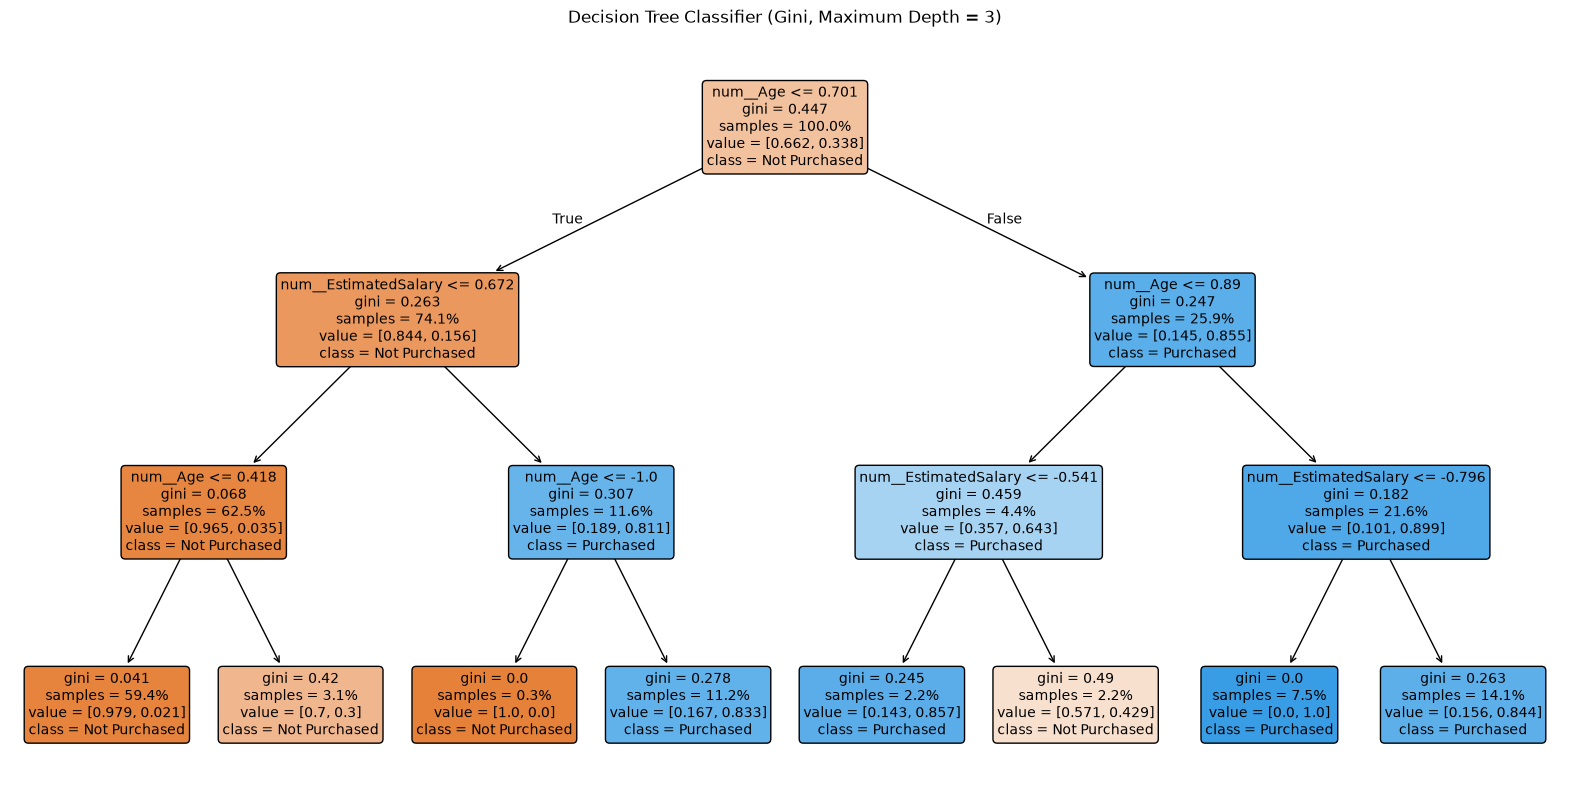

In [35]:
feature_names = preprocessor.get_feature_names_out()

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=feature_names,
    class_names=["Not Purchased", "Purchased"],
    filled=True,
    rounded=True,
    fontsize=10,
    proportion=True
)

plt.title("Decision Tree Classifier (Gini, Maximum Depth = 3)")
plt.show()

In [36]:
# Retrieve fitted StandardScaler
scaler = preprocessor.named_transformers_["num"]

# Retrieve original numerical feature names
num_features = ["Age", "EstimatedSalary"]

# Convert thresholds back to original units
age_original = 0.701 * scaler.scale_[0] + scaler.mean_[0]
salary_original_true = 0.672 * scaler.scale_[1] + scaler.mean_[1]
age_first_split = 0.89 * scaler.scale_[0] + scaler.mean_[0]

print(f"Age threshold original: {age_original:.1f} years")
print(f"Estimated Salary threshold: {salary_original_true:,.0f}")
print(f"Age threshold (first split): {age_first_split:.1f} years")

Age threshold original: 44.5 years
Estimated Salary threshold: 90,514
Age threshold (first split): 46.5 years


- The classifier determined that the most important features for predicting whether a user will purchase the product are Age and EstimatedSalary. The gender of an individual does not appear to be a significant factor in this decision-making process. The decision tree splits the data based on these two features, indicating that they have a stronger influence on the purchasing behavior of users.
- We start with the first split based on Age 44.5 years. At this point we assume that the client will not purchase the product. If the client is younger than 44.5 years, we move to the left side of the tree where we still assume they will not purchase the product. The next split is based on Estimated Salary 90k. If the client has an estimated salary less than 90k, we assume that they will not purchase the product. If they have an estimated salary greater than or equal to 90k, we assume that they will purchase the product.
- The right side of the tree is for clients older than 44.5 years. At this point we assume that the client will purchase the product. The next split is based on Age 46.5 years. If the client is younger than 46.5 years, we assume that they will purchase the product. If they are older than 46.5 years, we assume that they will not purchase the product.

- Limiting tree depth does improve interpretability by reducing the number of splits and making the decision-making process easier to understand.
- In this instance, by reducing the number of splits, we observe a higher accuracy and a more balanced confusion matrix, indicating that the model is better at correctly classifying both classes. The classification report also shows improved precision, recall, and F1-score for both classes, suggesting that the model is more effective in identifying true positives and minimizing false negatives.

### Task 2

In [45]:
# Configure Random Forest
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
rf_classifier.fit(X_train_preprocessed, y_train)

# Generate predictions
y_pred_rf = rf_classifier.predict(X_test_preprocessed)

In [46]:
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9

Confusion Matrix:
[[41  4]
 [ 4 31]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        45
           1       0.89      0.89      0.89        35

    accuracy                           0.90        80
   macro avg       0.90      0.90      0.90        80
weighted avg       0.90      0.90      0.90        80



                Feature  Importance
2              num__Age    0.604288
3  num__EstimatedSalary    0.389071
0    cat__Gender_Female    0.003646
1      cat__Gender_Male    0.002996


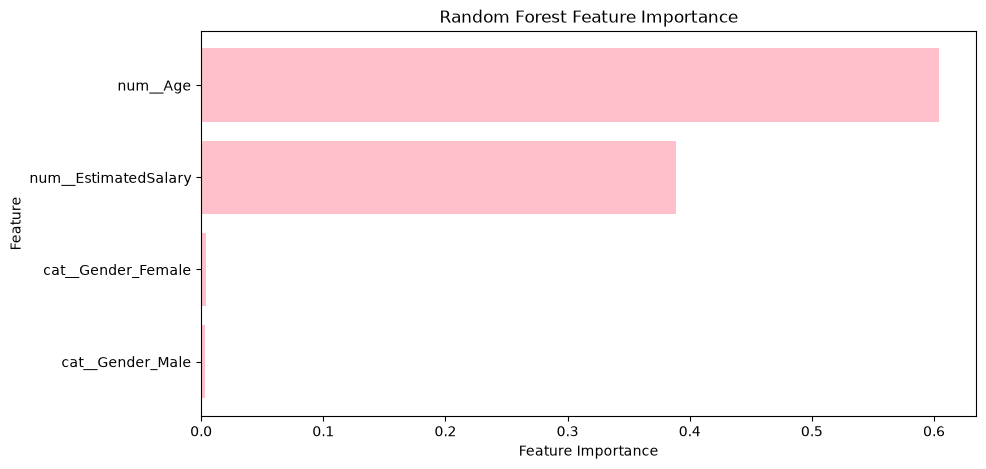

In [43]:
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({"Feature": feature_names, "Importance": rf_classifier.feature_importances_}).sort_values("Importance", ascending=False)

print(importance)

plt.figure(figsize=(10, 5))
plt.barh(importance["Feature"], importance["Importance"], color="pink")

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.show()

- The base Random Forest model reaches an accuracy of 90%. This just shy of the Decision Tree model with a maximum depth of 3, which achieved an accuracy of 91%. 
- Random Forests reduce variance by aggregating predictions from many diverse trees. Each tree may overfit slightly, but averaging their outputs cancels out individual errors. This leads to more stable, generalisable predictions and improved accuracy compared with a single tree.